# Controlled 3-state 2BSDE: time-, observation- and posterior-dependent benchmark

The dynamics, control set and terminal cost are:
$$
\Theta\in\{-1,0,1\},\qquad dY_t=u_t\Theta\,dt+dW_t,
\qquad u_t\in[-1,1],\qquad T=1,
$$
$$
dp_t^i=u_t b_i(p_t)\,dI_t,\qquad b_i(p)=p_i(\theta_i-m(p)).
$$
Define
$$
G(p)=\tfrac12(1-\|p\|^2),\quad m(p)=\sum_i p_i\theta_i,
\quad r(p)=\sum_i p_i\theta_i^2,\quad S(p)=\sum_i b_i(p)^2,
$$
$$
a(t)=(t-\tfrac12)^2,\qquad c(t)=1+\tfrac12(1-t),
\qquad \eta(t)=\tfrac12(1-t),
$$
$$
D(t,p)=2-c(t)S(p),\qquad N(t,y,p)=2a(t)+\eta(t)r(p)\sin y.
$$
The new running cost is
$$
k(t,y,p,u)=1+\tfrac12G(p)+\frac{3-t}{4}m(p)\cos y
+u^2-2a(t)u+\frac{N(t,y,p)^2}{2D(t,p)},
\qquad g(p)=G(p).
$$
The exact value and optimal feedback are
$$
\boxed{V(t,y,p)=c(t)G(p)+(1-t)\left(1+\tfrac12m(p)\cos y\right),
\qquad u^*(t,y,p)=\frac{N(t,y,p)}{D(t,p)}.}
$$
Including the mixed observation-posterior derivatives, the HJB residual is
$$
\partial_tV+\mathcal L^uV+k
=\frac{D(t,p)}2\left(u-u^*(t,y,p)\right)^2.
$$
Since $S(p)\le1/2$, $D(t,p)\ge5/4$ and $u^*\in[-2/5,4/5]$;
the optimum needs no clipping. For $y_0=0$, $p_0=(1/4,1/2,1/4)$,
$V_0=47/32=1.46875$ and $u_0^*=8/29$.

This is a constructed benchmark with an explicit solution. Its value, control,
gradient and full Hessian depend on the state; the posterior-posterior Hessian
block alone remains time-dependent. The original terminal cost is retained.

In [19]:
from pathlib import Path
import math
import sys

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from two_bsde.config import ModelConfig, HamiltonianConfig, TrainingConfig
from two_bsde.problem import BayesianControlProblem
from two_bsde.geometry import make_simplex_tangent_basis, SimplexGeometry
from two_bsde.hamiltonian import HamiltonianOptimizer
from two_bsde.twoBsdeStructure import GeometricTimeBlockAdaptive2BSDE
from two_bsde.dynamics import split_state, state_dynamics
from two_bsde.training import train_time_blocks
from two_bsde.evaluation import evaluate_time_blocks

DTYPE = torch.float64
DEVICE = torch.device("cpu")

# torch.manual_seed(42)
# np.random.seed(42)

In [20]:
config = ModelConfig(
    horizon=1.0,
    hidden_dim=1,
    observation_dim=1,
    control_dim=1,
    num_hidden_states=3,
    num_time_steps=30,
    network_width=64,
    network_depth=5,
    value_initial_guess=0.01,
    gamma_initial_scale=0.01,
)

ham_config = HamiltonianConfig(
    num_starts=12,
    num_steps=30,
    learning_rate=5e-2,
)

training_config = TrainingConfig(
    epochs=1500,
    batch_size=128,
    learning_rate=1e-4,
    gradient_clip=10.0,
    value_loss_weight=1.0,
    gradient_loss_weight=5.0,
)

basis = make_simplex_tangent_basis(
    config.num_hidden_states,
    dtype=DTYPE,
    device=DEVICE,
)

geometry = SimplexGeometry(
    observation_dim=config.observation_dim,
    basis=basis,
)

print("state_dim =", config.state_dim)
print("tangent_dim =", config.tangent_dim)

state_dim = 4
tangent_dim = 2


## Concrete problem

In [21]:
class ControlledThreeStateProblem(BayesianControlProblem):
    def __init__(self, config):
        super().__init__(config)
        if config.horizon != 1.0:
            raise ValueError("This benchmark uses horizon T=1.")

        self.theta = torch.tensor([-1.0, 0.0, 1.0], dtype=DTYPE, device=DEVICE)
        self.x_support = self.theta[:, None].clone()
        self.initial_observation = torch.tensor([0.0], dtype=DTYPE, device=DEVICE)
        self.initial_posterior = torch.tensor([0.25, 0.50, 0.25], dtype=DTYPE, device=DEVICE)
        self.control_low = torch.tensor([-1.0], dtype=DTYPE, device=DEVICE)
        self.control_high = torch.tensor([1.0], dtype=DTYPE, device=DEVICE)

        # Retained for compatibility with the original problem setup.
        # The time-block model instead applies each path's own minimiser.
        self.auxiliary_control_path = torch.zeros(
            config.num_time_steps, config.control_dim, dtype=DTYPE, device=DEVICE,
        )
        self.validate(config)

    def sensor(self, control, observation):
        lead_shape = control.shape[:-1]
        theta = self.theta.to(control).reshape(
            *([1] * len(lead_shape)), self.config.num_hidden_states, 1,
        )
        return control.unsqueeze(-2) * theta

    @staticmethod
    def a(time):
        return (time - 0.5) ** 2

    @staticmethod
    def c(time):
        return 1.0 + 0.5 * (1.0 - time)

    @staticmethod
    def eta(time):
        return 0.5 * (1.0 - time)

    def posterior_terms(self, state):
        p = state[..., self.config.observation_dim:]
        theta = self.theta.to(state)
        m = (p * theta).sum(dim=-1)
        r = (p * theta.square()).sum(dim=-1)
        b = p * (theta - m[..., None])
        G = 0.5 * (1.0 - p.square().sum(dim=-1))
        S = b.square().sum(dim=-1)
        return G, S, m, r

    def running_cost(self, state, control, *, time):
        time = torch.as_tensor(time, dtype=state.dtype, device=state.device)
        G, S, m, r = self.posterior_terms(state)
        y, u = state[..., 0], control[..., 0]
        a = self.a(time)
        D = 2.0 - self.c(time) * S
        N = 2.0 * a + self.eta(time) * r * torch.sin(y)
        return (
            1.0 + 0.5 * G + 0.25 * (3.0 - time) * m * torch.cos(y)
            + u.square() - 2.0 * a * u + 0.5 * N.square() / D
        )

    def terminal_cost(self, state):
        G, _, _, _ = self.posterior_terms(state)
        return G


problem = ControlledThreeStateProblem(config)
S0 = torch.cat((problem.initial_observation, problem.initial_posterior))
print("S0 =", S0)
print("theta =", problem.theta)
print("Control: each path uses its own Hamiltonian minimiser at every fine step.")

S0 = tensor([0.0000, 0.2500, 0.5000, 0.2500], dtype=torch.float64)
theta = tensor([-1.,  0.,  1.], dtype=torch.float64)
Control: each path uses its own Hamiltonian minimiser at every fine step.


## Analytic solution

The derivatives below use the posterior tangent projection
$P=I-\mathbf 1\mathbf 1^\top/3$. With $\theta=(-1,0,1)^\top$ and
$\eta(t)=(1-t)/2$,
$$
Z_y=-\eta m\sin y,\qquad Z_p=-cPp+\eta\theta\cos y,
$$
$$
\Gamma_{yy}=-\eta m\cos y,\qquad
\Gamma_{yp}=-\eta\sin y\,\theta^\top,\qquad
\Gamma_{pp}=-cP.
$$
The mixed block is essential because $Y$ and $p$ share the same Brownian motion.

In [22]:
def exact_value(time, state):
    time = torch.as_tensor(time, dtype=state.dtype, device=state.device)
    G, _, m, _ = problem.posterior_terms(state)
    y = state[..., 0]
    return problem.c(time) * G + (1.0 - time) * (1.0 + 0.5 * m * torch.cos(y))


def exact_gradient(time, state):
    time = torch.as_tensor(time, dtype=state.dtype, device=state.device)
    _, _, m, _ = problem.posterior_terms(state)
    y = state[..., 0]
    theta = problem.theta.to(state)
    eta = problem.eta(time)
    ambient = torch.zeros_like(state)
    ambient[..., 0] = -eta * m * torch.sin(y)
    ambient[..., config.observation_dim:] = (
        -problem.c(time)[..., None] * state[..., config.observation_dim:]
        + (eta * torch.cos(y))[..., None] * theta
    )
    return geometry.project_gradient(ambient)


def exact_hessian(time, state):
    time = torch.as_tensor(time, dtype=state.dtype, device=state.device)
    _, _, m, _ = problem.posterior_terms(state)
    y = state[..., 0]
    theta = problem.theta.to(state)
    eta = problem.eta(time)
    shape = state.shape[:-1] + (config.state_dim, config.state_dim)
    gamma = torch.zeros(shape, dtype=state.dtype, device=state.device)
    gamma[..., 0, 0] = -eta * m * torch.cos(y)
    mixed = -(eta * torch.sin(y))[..., None] * theta
    gamma[..., 0, config.observation_dim:] = mixed
    gamma[..., config.observation_dim:, 0] = mixed
    gamma[..., config.observation_dim:, config.observation_dim:] = (
        -problem.c(time)[..., None, None] * geometry.projector
    )
    return gamma


def exact_control(time, state):
    time = torch.as_tensor(time, dtype=state.dtype, device=state.device)
    _, S, _, r = problem.posterior_terms(state)
    y = state[..., 0]
    D = 2.0 - problem.c(time) * S
    N = 2.0 * problem.a(time) + problem.eta(time) * r * torch.sin(y)
    return (N / D).unsqueeze(-1)


V0_exact = exact_value(0.0, S0)
u0_exact = exact_control(0.0, S0)
print("exact V0 =", V0_exact.item())
print("exact u0* =", u0_exact.item())
assert abs(V0_exact.item() - 47.0 / 32.0) < 1e-12
assert abs(u0_exact.item() - 8.0 / 29.0) < 1e-12

exact V0 = 1.46875
exact u0* = 0.27586206896551724


## Verify the analytic HJB

In [23]:
def analytic_hjb_expression(time, state, control):
    drift, sigma, _ = state_dynamics(
        state, control, problem=problem, config=config, geometry=geometry,
    )
    G, _, m, _ = problem.posterior_terms(state)
    y = state[..., 0]
    time_derivative = -0.5 * G - 1.0 - 0.5 * m * torch.cos(y)
    running = problem.running_cost(state, control, time=time)
    z = exact_gradient(time, state)
    gamma = exact_hessian(time, state)
    first_order = (drift * z).sum(dim=-1)
    # Full Hessian contraction includes yy, yp, py and pp terms.
    second_order = 0.5 * torch.einsum("...ia,...ij,...ja->...", sigma, gamma, sigma)
    return time_derivative + running + first_order + second_order


test_states = torch.tensor(
    [[0.0, 0.20, 0.50, 0.30],
     [0.4, 0.70, 0.20, 0.10],
     [-0.6, 0.05, 0.20, 0.75]],
    dtype=DTYPE, device=DEVICE,
)

for time in [0.0, 0.25, 0.5, 0.9, 1.0]:
    u_exact = exact_control(time, test_states)
    hjb_at_exact = analytic_hjb_expression(time, test_states, u_exact)
    print(f"t={time:.2f}: analytic control = {u_exact[:, 0].cpu().numpy()}")
    print("         HJB at analytic control =", hjb_at_exact.cpu().numpy())
    assert torch.allclose(hjb_at_exact, torch.zeros_like(hjb_at_exact), atol=1e-12)

    _, S, _, _ = problem.posterior_terms(test_states)
    D = 2.0 - problem.c(time) * S
    for u_value in [-1.0, -0.5, 0.0, 0.5, 1.0]:
        u = torch.full((len(test_states), 1), u_value, dtype=DTYPE, device=DEVICE)
        residual = analytic_hjb_expression(time, test_states, u)
        square = 0.5 * D * (u[:, 0] - u_exact[:, 0]).square()
        assert torch.allclose(residual, square, atol=1e-12)
        assert torch.all(residual >= -1e-12)

assert torch.allclose(exact_value(1.0, test_states), problem.terminal_cost(test_states))
assert torch.allclose(
    exact_gradient(1.0, test_states),
    geometry.project_gradient(problem.terminal_gradient(test_states)),
)
print("analytic HJB and terminal checks: PASSED")

t=0.00: analytic control = [0.27558838 0.35983721 0.14552467]
         HJB at analytic control = [-1.87350135e-16  9.71445147e-17  8.32667268e-17]
t=0.25: analytic control = [ 0.06831441  0.13162721 -0.02344473]
         HJB at analytic control = [-1.00613962e-16 -6.93889390e-17 -2.77555756e-17]
t=0.50: analytic control = [ 0.          0.04205382 -0.05933651]
         HJB at analytic control = [-4.16333634e-17  2.77555756e-17  1.52655666e-16]
t=0.90: analytic control = [0.17112208 0.17890937 0.15501005]
         HJB at analytic control = [-3.20056481e-16  1.21430643e-17  2.74086309e-16]
t=1.00: analytic control = [0.26649611 0.26573129 0.26007126]
         HJB at analytic control = [ 1.21430643e-16  5.89805982e-17 -7.37257477e-18]
analytic HJB and terminal checks: PASSED


## Build the time-block 2BSDE model

Use the same 3 shared blocks and 30 fine time steps. All paths start from the
original initial state. Each path applies its own fine-step Hamiltonian minimiser.

In [24]:
hamiltonian_optimizer = HamiltonianOptimizer(
    problem=problem,
    model_config=config,
    optimizer_config=ham_config,
    geometry=geometry,
)

model = GeometricTimeBlockAdaptive2BSDE(
    problem=problem,
    config=config,
    geometry=geometry,
    hamiltonian_optimizer=hamiltonian_optimizer,
    num_blocks=3,
).to(device=DEVICE, dtype=DTYPE)

print("number of time blocks =", model.num_blocks)


number of time blocks = 3


## Train the time-block 2BSDE


In [25]:
history = train_time_blocks(
    model,
    training_config=training_config,
    sample_start_times=False,  # start at t=0, as in the original notebook
    # boundary_weight=0.0,     # uncomment to disable the boundary penalty
    verbose=True,
)

epoch=   1  start_step=  0  total_loss=2.707e+00  terminal_value=2.142e+00  terminal_gradient=1.892e-02  consistency=4.711e-01  boundary=1.426e-05  mean_start_value=0.010608
epoch= 150  start_step=  0  total_loss=4.149e-01  terminal_value=2.511e-01  terminal_gradient=8.543e-05  consistency=1.139e-01  boundary=4.951e-01  mean_start_value=0.971131
epoch= 300  start_step=  0  total_loss=1.209e-01  terminal_value=2.679e-02  terminal_gradient=3.250e-05  consistency=5.599e-02  boundary=3.798e-01  mean_start_value=1.310258
epoch= 450  start_step=  0  total_loss=3.916e-02  terminal_value=7.131e-04  terminal_gradient=8.094e-06  consistency=2.106e-02  boundary=1.735e-01  mean_start_value=1.463770
epoch= 600  start_step=  0  total_loss=2.027e-02  terminal_value=6.934e-04  terminal_gradient=3.825e-06  consistency=1.657e-02  boundary=2.984e-02  mean_start_value=1.465249
epoch= 750  start_step=  0  total_loss=1.640e-02  terminal_value=5.674e-04  terminal_gradient=3.295e-06  consistency=1.397e-02  bo

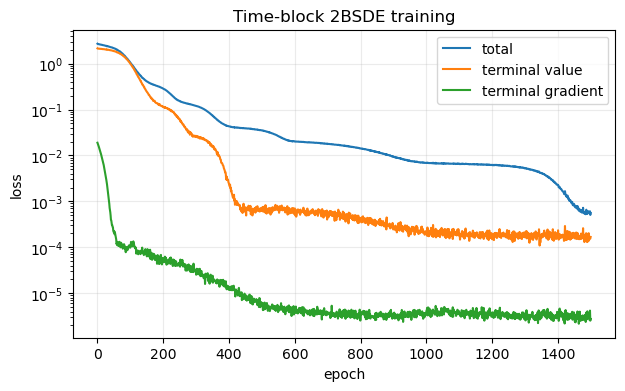

In [26]:
plt.figure(figsize=(7, 4))
plt.semilogy(history.total_loss, label="total")
plt.semilogy(history.terminal_value_loss, label="terminal value")
plt.semilogy(history.terminal_gradient_loss, label="terminal gradient")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Time-block 2BSDE training")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## Compare the learned initial value with the analytic solution


In [27]:
with torch.no_grad():
    V0_learned = model.value(0.0, S0)

print("VALUE")
print(" learned:", V0_learned.item())
print(" exact:  ", V0_exact.item())
print(" abs err:", abs(V0_learned.item() - V0_exact.item()))


VALUE
 learned: 1.469187368276957
 exact:   1.46875
 abs err: 0.0004373682769569509


## Test the inner Hamiltonian optimizer with the analytic derivatives

Test several posteriors and times. For scalar controls the optimizer searches
a uniform grid, so compare with the continuous analytic optimum using half the
grid spacing as the tolerance. This separates the control-search discretisation
from errors in the learned $Z$ and $\Gamma$.

In [28]:
state_batch = torch.tensor(
    [[0.0, 0.25, 0.50, 0.25],
     [0.2, 0.10, 0.20, 0.70],
     [-0.3, 0.65, 0.25, 0.10]],
    dtype=DTYPE, device=DEVICE,
)

grid_size = max(81, 20 * ham_config.num_starts + 1)
grid_spacing = (problem.control_high - problem.control_low).item() / (grid_size - 1)
print("control-grid spacing =", grid_spacing)
print("exact-derivative tolerance =", 0.5 * grid_spacing)

with torch.no_grad():
    for time in [0.0, 0.25, 0.5, 0.9]:
        _, u_from_exact_derivatives = hamiltonian_optimizer.minimise(
            state_batch,
            exact_gradient(time, state_batch),
            exact_hessian(time, state_batch),
            time=time,
        )
        u_analytic = exact_control(time, state_batch)
        error = (u_from_exact_derivatives - u_analytic).abs().max().item()
        print(f"t={time:.2f}")
        print(" numerical u* =", u_from_exact_derivatives[:, 0].cpu().numpy())
        print(" analytic  u* =", u_analytic[:, 0].cpu().numpy())
        print(" max abs error =", error)
        assert error <= 0.5 * grid_spacing + 1e-10

control-grid spacing = 0.008333333333333333
exact-derivative tolerance = 0.004166666666666667
t=0.00
 numerical u* = [0.275      0.31666667 0.21666667]
 analytic  u* = [0.27586207 0.31796956 0.21534148]
 max abs error = 0.0013251893672900916
t=0.25
 numerical u* = [0.06666667 0.1        0.025     ]
 analytic  u* = [0.06837607 0.10047942 0.02297168]
 max abs error = 0.0020283223250056187
t=0.50
 numerical u* = [ 1.38777878e-17  2.50000000e-02 -3.33333333e-02]
 analytic  u* = [ 0.          0.02145457 -0.03012413]
 max abs error = 0.0035454286398422206
t=0.90
 numerical u* = [0.175      0.175      0.16666667]
 analytic  u* = [0.17123746 0.17484154 0.16563185]
 max abs error = 0.0037625418060200366


## Fresh-path 2BSDE evaluation: paired analytic comparisons

For each simulated numerical state $S_k^{(b)}=(Y_k^{(b)},p_k^{(b)})$, compare
$$
u_k^{\mathrm{num},(b)}\quad\hbox{with}\quad
u^*(t_k,Y_k^{(b)},p_k^{(b)}).
$$
The analytic feedback is evaluated at **the same observation, posterior and time**,
so no independent analytic trajectory is needed. Controls and Hessians use the
state at the **start** of each step; value and gradient paths also include $T$.

We report paired MAE and RMSE, alongside individual paired paths and ensemble
summaries. The analytic 10–90% band measures variation across paths, not a
confidence interval. Its two edges are plotted explicitly and the vertical
axis is allowed to autoscale. The exact control can be negative or cross zero,
so we use absolute errors rather than relative errors.

The analytic reference is exact for the continuous-time problem; the numerical
state paths use the existing Euler scheme and posterior stabilisation.

In [36]:
result = evaluate_time_blocks(model, num_paths=500, evaluate_policy=False)
paths = result.paths

with torch.no_grad():
    times = paths["time_path"]                    # [steps+1]
    control_times = times[:-1]                    # [steps]
    states = paths["S_path"]                      # [paths, steps+1, state_dim]
    u_star_path = paths["u_star_path"][..., 0]    # [paths, steps]
    u_exact_path = exact_control(control_times, states[:, :-1])[..., 0]
    control_error = u_star_path - u_exact_path
    mean_u_by_time = u_star_path.mean(dim=0)
    mean_exact_u_by_time = u_exact_path.mean(dim=0)
    mae_u_by_time = control_error.abs().mean(dim=0)
    rmse_u_by_time = control_error.square().mean(dim=0).sqrt()
    q10_exact, q90_exact = torch.quantile(
        u_exact_path, torch.tensor([0.1, 0.9], dtype=DTYPE, device=DEVICE), dim=0,
    )

    V_exact_path = exact_value(times, states)
    value_head_error = paths["value_path"] - V_exact_path
    propagated_value_error = paths["R_path"] - V_exact_path

assert torch.equal(paths["u_aux_path"], paths["u_star_path"])
print("PAIRED CONTROL COMPARISON AT THE SAME STATES")
print(" mean absolute error =", control_error.abs().mean().item())
print(" root mean square error =", control_error.square().mean().sqrt().item())
print(" maximum absolute error =", control_error.abs().max().item())
print(" maximum analytic 10-90% band width =", (q90_exact - q10_exact).max().item())
print("PAIRED VALUE COMPARISON AT THE SAME STATES")
print(" value-network RMSE =", value_head_error.square().mean().sqrt().item())
print(" propagated R RMSE  =", propagated_value_error.square().mean().sqrt().item())
print(" posterior correction rate =", result.diagnostics["posterior_correction_rate"])

PAIRED CONTROL COMPARISON AT THE SAME STATES
 mean absolute error = 0.026497756044607475
 root mean square error = 0.03437337173365999
 maximum absolute error = 0.11633323761103674
 maximum analytic 10-90% band width = 0.12613935968891213
PAIRED VALUE COMPARISON AT THE SAME STATES
 value-network RMSE = 0.019756476312472012
 propagated R RMSE  = 0.011978192297436385
 posterior correction rate = 0.0


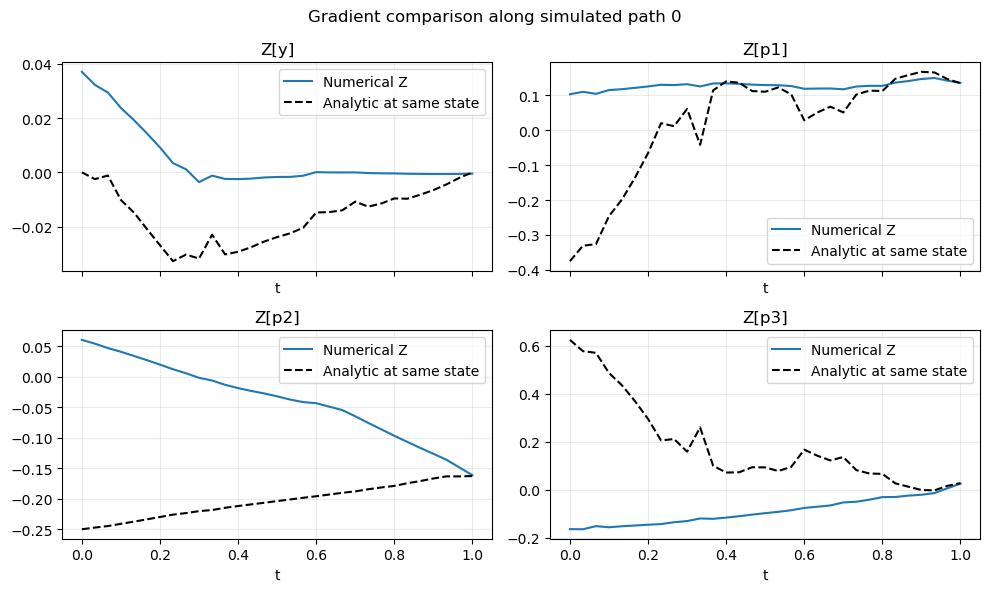

In [37]:
path_id = 0

with torch.no_grad():
    Z_learned = paths["Z_path"][path_id].detach().cpu()
    Z_exact = exact_gradient(times, states[path_id]).detach().cpu()

time_numpy = times.detach().cpu().numpy()
labels = ["y", "p1", "p2", "p3"]
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(time_numpy, Z_learned[:, i].numpy(), label="Numerical Z")
    ax.plot(time_numpy, Z_exact[:, i].numpy(), "--", color="black", label="Analytic at same state")
    ax.set_title(f"Z[{labels[i]}]")
    ax.set_xlabel("t")
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f"Gradient comparison along simulated path {path_id}")
plt.tight_layout()
plt.show()

In [38]:
with torch.no_grad():
    Gamma0_learned = model.blocks[0].gamma(0.0, S0)
    Gamma0_exact = exact_hessian(0.0, S0)

print("HESSIAN AT t=0")
print(" learned:\n", Gamma0_learned)
print(" exact:\n", Gamma0_exact)
print(" Frobenius error:", torch.linalg.matrix_norm(Gamma0_learned - Gamma0_exact, ord="fro").item())

HESSIAN AT t=0
 learned:
 tensor([[-0.0022,  0.0331,  0.0049, -0.0380],
        [ 0.0331, -0.1762,  0.0719,  0.1043],
        [ 0.0049,  0.0719, -0.1290,  0.0572],
        [-0.0380,  0.1043,  0.0572, -0.1615]], dtype=torch.float64)
 exact:
 tensor([[-0.0000,  0.0000, -0.0000, -0.0000],
        [ 0.0000, -1.0000,  0.5000,  0.5000],
        [-0.0000,  0.5000, -1.0000,  0.5000],
        [-0.0000,  0.5000,  0.5000, -1.0000]], dtype=torch.float64)
 Frobenius error: 1.7937133161743242


Mean Hessian error: 1.2500486917181879


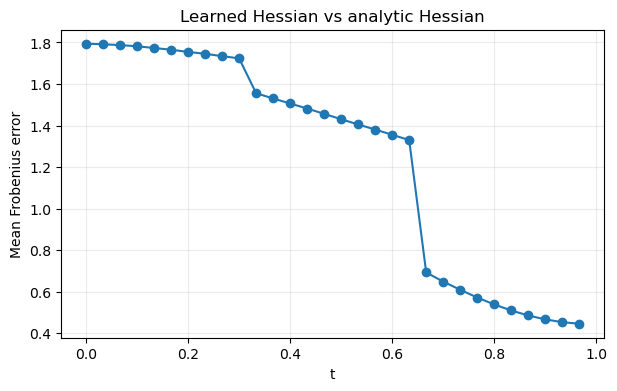

In [39]:
with torch.no_grad():
    # Gamma at step k belongs to the state at the START of that step.
    Gamma_learned = paths["Gamma_path"]           # [paths, steps, 4, 4]
    Gamma_exact = exact_hessian(control_times, states[:, :-1])
    error = torch.linalg.matrix_norm(
        Gamma_learned - Gamma_exact, ord="fro", dim=(-2, -1),
    )                                           # [paths, steps]

print("Mean Hessian error:", error.mean().item())
plt.figure(figsize=(7, 4))
plt.plot(control_times.cpu().numpy(), error.mean(dim=0).cpu().numpy(), marker="o")
plt.xlabel("t")
plt.ylabel("Mean Frobenius error")
plt.title("Learned Hessian vs analytic Hessian")
plt.grid(alpha=0.25)
plt.show()

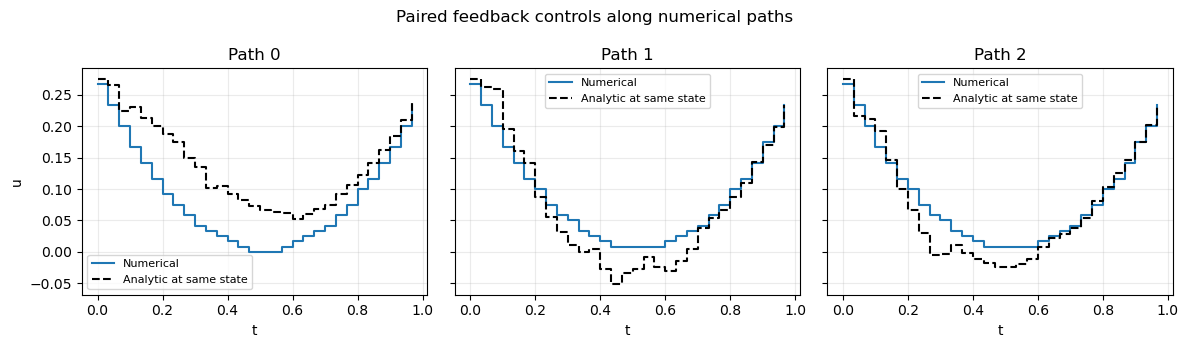

In [40]:
time_grid = control_times.detach().cpu().numpy()

# Individual paired paths show differences hidden by ensemble means.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True, sharey=True)
for path_id, ax in enumerate(axes):
    ax.step(time_grid, u_star_path[path_id].cpu().numpy(), where="post", label="Numerical")
    ax.step(time_grid, u_exact_path[path_id].cpu().numpy(), where="post", linestyle="--",
            color="black", label="Analytic at same state")
    ax.set_title(f"Path {path_id}")
    ax.set_xlabel("t")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel("u")
fig.suptitle("Paired feedback controls along numerical paths")
plt.tight_layout()
plt.show()

Ensemble, 500 simulated paths, 
$$
    \operatorname{MAE}(t)=\frac{1}{N} \sum_{i=1}^N\left|e_i\right|.
$$
$$
    \operatorname{RMSE}(t)=\sqrt{\frac{1}{N} \sum_{i=1}^N e_i^2}.
$$

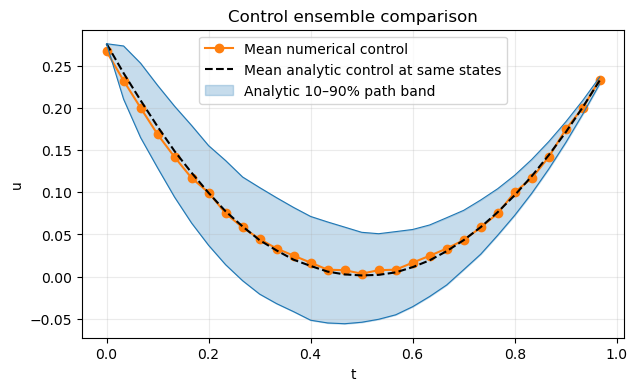

In [41]:
plt.figure(figsize=(7, 4))
plt.plot(time_grid, mean_u_by_time.cpu().numpy(), marker="o", color="tab:orange",
         label="Mean numerical control")
plt.plot(time_grid, mean_exact_u_by_time.cpu().numpy(), "--", color="black",
         label="Mean analytic control at same states")
plt.fill_between(time_grid, q10_exact.cpu().numpy(), q90_exact.cpu().numpy(),
                 color="tab:blue", alpha=0.25, label="Analytic 10–90% path band")
plt.plot(time_grid, q10_exact.cpu().numpy(), color="tab:blue", linewidth=0.8)
plt.plot(time_grid, q90_exact.cpu().numpy(), color="tab:blue", linewidth=0.8)
plt.xlabel("t")
plt.ylabel("u")
plt.title("Control ensemble comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

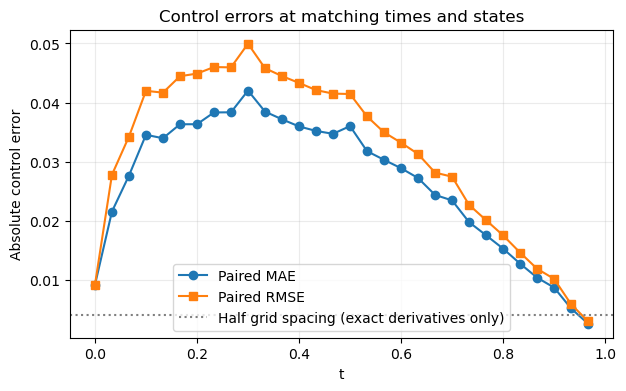

In [42]:
plt.figure(figsize=(7, 4))
plt.plot(time_grid, mae_u_by_time.cpu().numpy(), marker="o", label="Paired MAE")
plt.plot(time_grid, rmse_u_by_time.cpu().numpy(), marker="s", label="Paired RMSE")
plt.axhline(0.5 * grid_spacing, color="gray", linestyle=":",
            label="Half grid spacing (exact derivatives only)")
plt.xlabel("t")
plt.ylabel("Absolute control error")
plt.title("Control errors at matching times and states")
plt.legend()
plt.grid(alpha=0.25)
plt.show()